In [3]:
import os
import re
import random
import numpy as np
import pandas as pd
import torch
import sklearn.metrics as skm

from google.colab import drive
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from transformers import RobertaForSequenceClassification
from tokenizers import Tokenizer, normalizers
from tokenizers.normalizers import StripAccents, Replace
from tokenizers.processors import TemplateProcessing
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import PreTokenizer
from tokenizers import NormalizedString, PreTokenizedString
from typing import List
from clang import cindex
from pathlib import Path

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [7]:
drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/VulnSight')
DATA_ROOT = PROJECT_ROOT / 'finetune'

# Select the dataset whose fine-tuned MLP model you want to test.
mydataset = 'devign'
TASK = 'function'    # used for D2A
MAX_LENGTH = 512
BATCH_SIZE = 16

TOKENIZER_VOCAB = PROJECT_ROOT / 'tokenizer' / 'drapgh-vocab.json'
TOKENIZER_MERGES = PROJECT_ROOT / 'tokenizer' / 'drapgh-merges.txt'
MODEL_PATH = Path("/content/drive/MyDrive/VulnSight/models/VulSight-MLP_devign/checkpoint-5464")

print('Project root exists:', PROJECT_ROOT.exists(), PROJECT_ROOT)
print('Dataset root exists:', DATA_ROOT.exists(), DATA_ROOT)
print('Tokenizer vocab exists:', TOKENIZER_VOCAB.exists())
print('Tokenizer merges exists:', TOKENIZER_MERGES.exists())
print('Fine-tuned MLP model exists:', MODEL_PATH.exists(), MODEL_PATH)

if not TOKENIZER_VOCAB.exists() or not TOKENIZER_MERGES.exists():
    raise FileNotFoundError('Tokenizer vocab/merges files were not found. Check TOKENIZER_VOCAB and TOKENIZER_MERGES.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root exists: True /content/drive/MyDrive/VulnSight
Dataset root exists: True /content/drive/MyDrive/VulnSight/finetune
Tokenizer vocab exists: True
Tokenizer merges exists: True
Fine-tuned MLP model exists: True /content/drive/MyDrive/VulnSight/models/VulSight-MLP_devign/checkpoint-5464


## Load the custom Clang + BPE tokenizer

In [8]:
class MyTokenizer:
    cidx = cindex.Index.create()

    def clang_split(self, i: int, normalized_string: NormalizedString) -> List[NormalizedString]:
        tokens = []
        tu = self.cidx.parse(
            "tmp.c",
            args=["-x", "c++", "-std=c++17"],
            unsaved_files=[("tmp.c", str(normalized_string.original))],
            options=0,
        )
        for token in tu.get_tokens(extent=tu.cursor.extent):
            spelling = token.spelling.strip()
            if spelling:
                tokens.append(NormalizedString(spelling))
        return tokens

    def pre_tokenize(self, pretok: PreTokenizedString):
        pretok.split(self.clang_split)


vocab, merges = BPE.read_file(vocab=str(TOKENIZER_VOCAB), merges=str(TOKENIZER_MERGES))
my_tokenizer = Tokenizer(BPE(vocab, merges, unk_token="<unk>"))
my_tokenizer.normalizer = normalizers.Sequence([StripAccents(), Replace(" ", "Ä")])
my_tokenizer.pre_tokenizer = PreTokenizer.custom(MyTokenizer())
my_tokenizer.post_processor = TemplateProcessing(
    single="<s> $A </s>",
    special_tokens=[("<s>", 0), ("<pad>", 1), ("</s>", 2), ("<unk>", 3), ("<mask>", 4)],
)
my_tokenizer.enable_truncation(max_length=MAX_LENGTH)
my_tokenizer.enable_padding(direction="right", pad_id=1, pad_type_id=0, pad_token="<pad>")
print("Custom tokenizer loaded.")

Custom tokenizer loaded.


In [9]:
def cleaner(code):
    # Remove C/C++ line and block comments, then normalize whitespace.
    code = "" if pd.isna(code) else str(code)
    pat = re.compile(r'(/\*.*?\*/)|(//[^\n]*)', flags=re.DOTALL)
    code = re.sub(pat, '', code)
    code = code.replace('\n', ' ').replace('\t', ' ')
    return code.strip()


def replace_colname(df):
    # Rename only when the canonical destination column is not already present.
    rename_map = {}
    if 'func' not in df.columns:
        for candidate in ('functionSource', 'code', 'function'):
            if candidate in df.columns:
                rename_map[candidate] = 'func'
                break
    if 'target' not in df.columns:
        for candidate in ('label', 'combine', 'vul'):
            if candidate in df.columns:
                rename_map[candidate] = 'target'
                break
    return df.rename(columns=rename_map)

In [10]:
if mydataset.lower() == 'devign':
    dataset_dir = PROJECT_ROOT / 'finetune' / 'devign'
    test_index_path = dataset_dir / 'test.txt'
    data_path = dataset_dir / 'Devign.json'

    for path in (test_index_path, data_path):
        if not path.exists():
            raise FileNotFoundError(f'Required Devign file not found: {path}')

    with open(test_index_path, 'r', encoding='utf-8') as f:
        test_indices = sorted({int(line.strip()) for line in f if line.strip()})

    full_df = pd.read_json(data_path)
    if test_indices and (min(test_indices) < 0 or max(test_indices) >= len(full_df)):
        raise IndexError('Devign test.txt contains indices outside the range of Devign.json.')
    test_df = full_df.iloc[test_indices].copy()
    del full_df

elif mydataset.lower() == 'd2a':
    dataset_dir = PROJECT_ROOT / 'finetune' / 'd2a' / TASK
    test_path = dataset_dir / f'd2a_lbv1_{TASK}_test.csv'
    if not test_path.exists():
        raise FileNotFoundError(f'Required D2A test file not found: {test_path}')
    test_df = pd.read_csv(test_path)

else:
    dataset_dir = PROJECT_ROOT / 'finetune' / mydataset.lower()
    test_path = dataset_dir / f'{mydataset.lower()}_test.pkl'
    if not test_path.exists():
        raise FileNotFoundError(
            f'Required test file not found: {test_path}\n'
            'Check the dataset folder and the exact test filename.'
        )
    test_df = pd.read_pickle(test_path)

test_df = replace_colname(test_df)
print('Loaded test dataset:', mydataset)
print('Test dataframe shape:', test_df.shape)
print('Test dataframe columns:', test_df.columns.tolist())

Loaded test dataset: devign
Test dataframe shape: (2732, 4)
Test dataframe columns: ['project', 'commit_id', 'target', 'func']


In [11]:
class MyCustomDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
        n = len(labels)
        assert len(encodings['input_ids']) == n
        assert len(encodings['attention_mask']) == n

    def __getitem__(self, idx):
        return {
            'input_ids': torch.tensor(self.encodings['input_ids'][idx], dtype=torch.long),
            'attention_mask': torch.tensor(self.encodings['attention_mask'][idx], dtype=torch.long),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long),
        }

    def __len__(self):
        return len(self.labels)


def get_code_column(df):
    for col in ('func', 'code', 'functionSource', 'function'):
        if col in df.columns:
            return col
    raise ValueError(f'No code column found. Available columns: {df.columns.tolist()}')


def get_label_column(df):
    for col in ('target', 'label', 'combine', 'vul'):
        if col in df.columns:
            return col
    raise ValueError(f'No label column found. Available columns: {df.columns.tolist()}')


code_col = get_code_column(test_df)
label_col = get_label_column(test_df)

# Remove rows with missing labels
test_df = test_df.loc[
    test_df[label_col].notna(),
    [code_col, label_col]
].copy()

# Clean source code
test_df[code_col] = (
    test_df[code_col]
    .fillna('')
    .astype(str)
    .map(cleaner)
)

# Remove empty or whitespace-only source code
test_df = test_df.loc[
    test_df[code_col].str.strip().ne('')
].copy()

test_df = test_df.reset_index(drop=True)

print("Testing samples after cleaning:", len(test_df))
print("Empty source code samples:", test_df[code_col].str.strip().eq('').sum())

Testing samples after cleaning: 2732
Empty source code samples: 0


In [12]:
raw_labels = pd.to_numeric(test_df[label_col], errors='raise')
unique_labels = set(raw_labels.unique().tolist())
if not unique_labels.issubset({0, 1, 0.0, 1.0}):
    raise ValueError(
        f'Test labels must be binary 0/1, but found {sorted(unique_labels, key=str)}. '
        'Map the dataset labels to 0 and 1 before evaluation.'
    )

labels = raw_labels.astype(int).tolist()
if len(labels) == 0:
    raise ValueError('The test dataset contains no rows with valid labels.')

test_encodings = my_tokenizer.encode_batch(test_df[code_col].tolist())
pad_id = my_tokenizer.token_to_id('<pad>')
if pad_id is None:
    raise ValueError('Tokenizer vocabulary does not contain the <pad> token.')

In [13]:
input_ids, attention_masks = [], []
for enc in test_encodings:
    ids = enc.ids[:MAX_LENGTH]
    mask = enc.attention_mask[:MAX_LENGTH]
    pad_length = MAX_LENGTH - len(ids)
    input_ids.append(ids + [pad_id] * pad_length)
    attention_masks.append(mask + [0] * pad_length)

test_dataset = MyCustomDataset(
    {'input_ids': input_ids, 'attention_mask': attention_masks},
    labels
)
print('Tokenized test samples:', len(test_dataset))
print('Input sequence length:', MAX_LENGTH)
print('Test label counts:', pd.Series(labels).value_counts().sort_index().to_dict())

Tokenized test samples: 2732
Input sequence length: 512
Test label counts: {0: 1477, 1: 1255}


In [14]:
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print('Test batches:', len(test_loader))
print('Batch size:', BATCH_SIZE)

Test batches: 171
Batch size: 16


In [15]:
if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f'Fine-tuned MLP model directory not found: {MODEL_PATH}\n'
        'Confirm that the model was saved in this directory and that mydataset matches '
        'the dataset used during fine-tuning.'
    )

model = RobertaForSequenceClassification.from_pretrained(str(MODEL_PATH))
if model.config.num_labels != 2:
    raise ValueError(
        f'Expected a binary classifier with 2 labels; model has {model.config.num_labels}.'
    )

model.to(device)
model.eval()

print('Loaded model:', MODEL_PATH)
print('Number of parameters:', model.num_parameters())
print('Device:', device)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loaded model: /content/drive/MyDrive/VulnSight/models/VulSight-MLP_devign/checkpoint-5464
Number of parameters: 124836866
Device: cuda


In [16]:
all_labels = []
all_predictions = []
all_probabilities = []

model.eval()
with torch.no_grad():
    for batch in test_loader:
        batch_input_ids = batch['input_ids'].to(device)
        batch_attention_mask = batch['attention_mask'].to(device)
        batch_labels = batch['labels'].to(device)

        outputs = model(
            input_ids=batch_input_ids,
            attention_mask=batch_attention_mask
        )
        probabilities = torch.softmax(outputs.logits, dim=1)
        predictions = torch.argmax(probabilities, dim=1)

        all_labels.extend(batch_labels.cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())
        all_probabilities.extend(probabilities[:, 1].cpu().tolist())

if not all_labels:
    raise ValueError('No predictions were produced. Check the test dataset and DataLoader.')

print('Inference complete. Predictions:', len(all_predictions))

Inference complete. Predictions: 2732


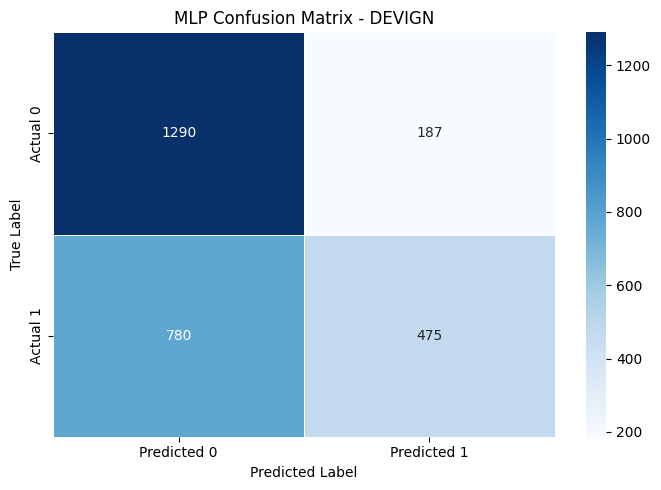

Confusion Matrix:
[[1290  187]
 [ 780  475]]
TN: 1290 | FP: 187 | FN: 780 | TP: 475

Evaluation Metrics:


,model_type,dataset,num_samples,accuracy,precision,recall,f1_score,pr_auc,roc_auc,mcc,tn,fp,fn,tp
0,MLP,devign,2732,0.646047,0.717523,0.378486,0.495566,0.689025,0.709855,0.292946,1290,187,780,475



Saved result files:
Evaluation metrics CSV: /content/drive/MyDrive/VulnSight/results/MLP/devign/devign_evaluation_metrics.csv
Confusion matrix CSV: /content/drive/MyDrive/VulnSight/results/MLP/devign/devign_confusion_matrix.csv
Confusion matrix image: /content/drive/MyDrive/VulnSight/results/MLP/devign/devign_confusion_matrix.png


In [17]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import sklearn.metrics as skm

# ==========================================
# 1. Calculate confusion matrix
# ==========================================
confusion = skm.confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = confusion.ravel()

# ==========================================
# 2. Evaluation metrics
# ==========================================
metrics = {
    "model_type": "MLP",
    "dataset": mydataset.lower(),
    "num_samples": len(all_labels),
    "accuracy": skm.accuracy_score(
        all_labels, all_predictions
    ),
    "precision": skm.precision_score(
        all_labels, all_predictions, zero_division=0
    ),
    "recall": skm.recall_score(
        all_labels, all_predictions, zero_division=0
    ),
    "f1_score": skm.f1_score(
        all_labels, all_predictions, zero_division=0
    ),
    "pr_auc": (
        skm.average_precision_score(
            all_labels, all_probabilities
        )
        if len(set(all_labels)) == 2 else None
    ),
    "roc_auc": (
        skm.roc_auc_score(
            all_labels, all_probabilities
        )
        if len(set(all_labels)) == 2 else None
    ),
    "mcc": skm.matthews_corrcoef(
        all_labels, all_predictions
    ),
    "tn": int(tn),
    "fp": int(fp),
    "fn": int(fn),
    "tp": int(tp),
}

# ==========================================
# 3. Create results directory
# ==========================================
RESULTS_DIR = (
    PROJECT_ROOT / "results" / "MLP" / mydataset.lower()
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 4. Save evaluation metrics as CSV
# ==========================================
metrics_path = (
    RESULTS_DIR /
    f"{mydataset.lower()}_evaluation_metrics.csv"
)

pd.DataFrame([metrics]).to_csv(
    metrics_path, index=False
)

# ==========================================
# 5. Save confusion matrix as CSV
# ==========================================
confusion_df = pd.DataFrame(
    confusion,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
)

confusion_csv_path = (
    RESULTS_DIR /
    f"{mydataset.lower()}_confusion_matrix.csv"
)

confusion_df.to_csv(confusion_csv_path)

# ==========================================
# 6. Display and save confusion matrix heatmap
# ==========================================
plt.figure(figsize=(7, 5))

sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"],
    linewidths=0.5,
    cbar=True
)

plt.title(
    f"MLP Confusion Matrix - {mydataset.upper()}"
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()

confusion_image_path = (
    RESULTS_DIR /
    f"{mydataset.lower()}_confusion_matrix.png"
)

plt.savefig(
    confusion_image_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==========================================
# 7. Print results and saved paths
# ==========================================
print("Confusion Matrix:")
print(confusion)
print(f"TN: {tn} | FP: {fp} | FN: {fn} | TP: {tp}")

print("\nEvaluation Metrics:")
display(pd.DataFrame([metrics]))

print("\nSaved result files:")
print("Evaluation metrics CSV:", metrics_path)
print("Confusion matrix CSV:", confusion_csv_path)
print("Confusion matrix image:", confusion_image_path)